In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

print("Libraries Imported Successfully ✅")


Libraries Imported Successfully ✅


In [ ]:
df = pd.read_csv('/content/WA_Fn-UseC_-HR-Employee-Attrition (1).csv')

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Dataset Shape: (1470, 35)

Missing Values:
 Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany            

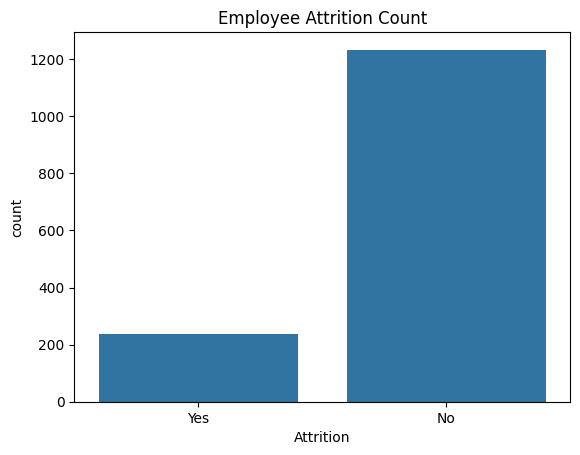

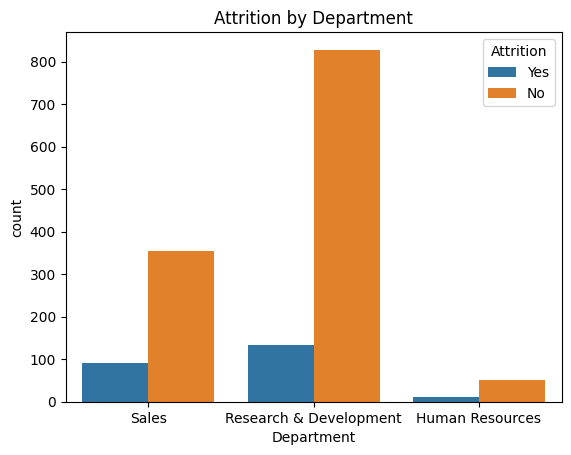

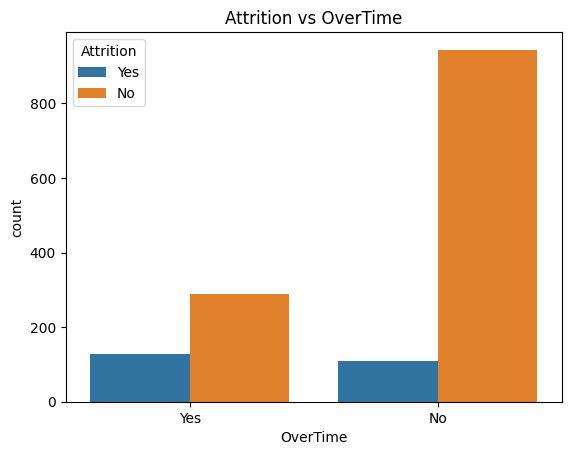

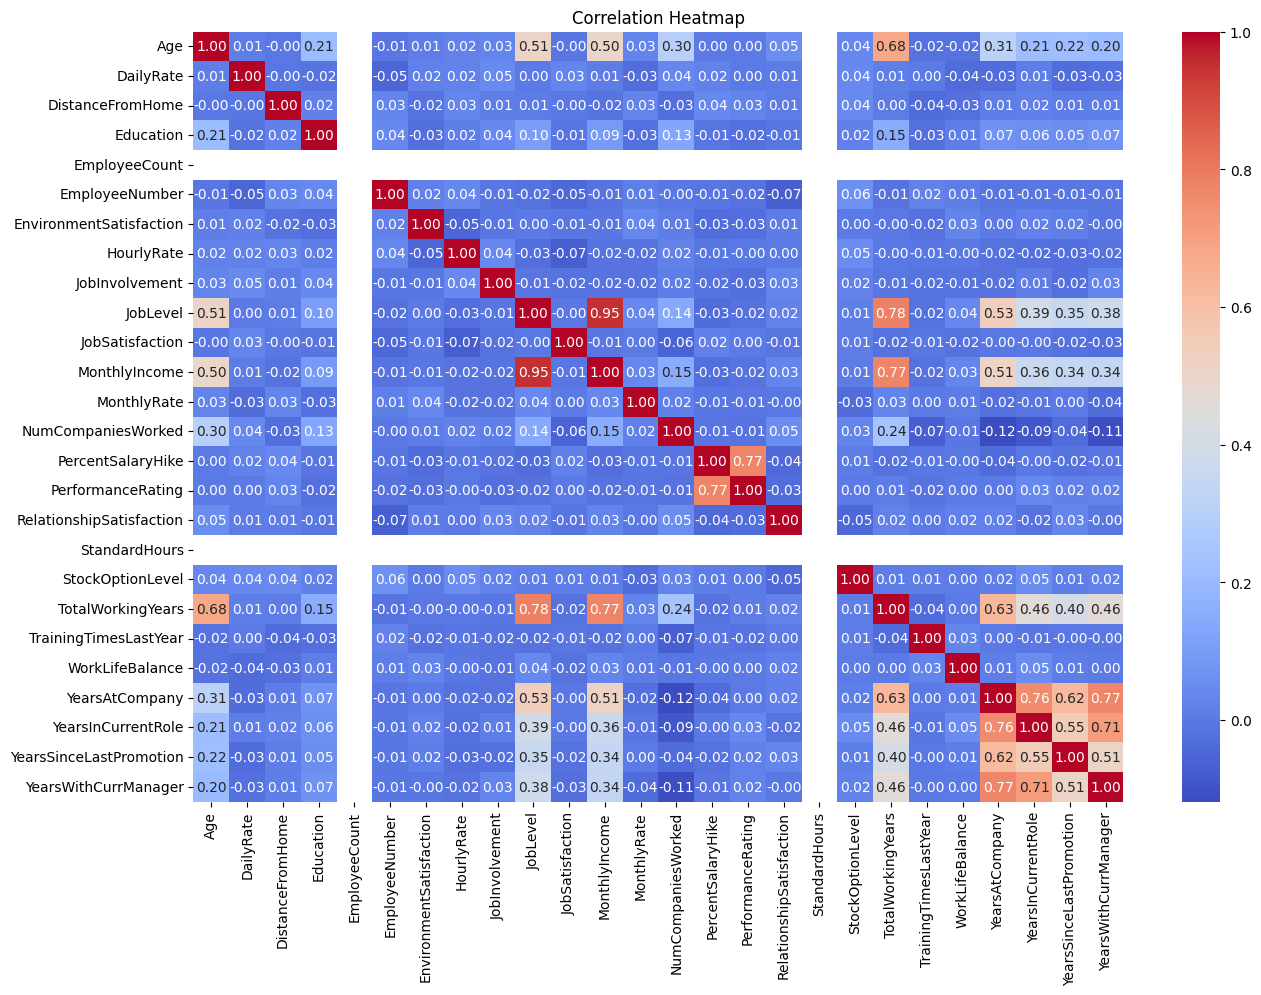

In [ ]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
df.describe()
sns.countplot(x='Attrition', data=df)
plt.title("Employee Attrition Count")
plt.show()
sns.countplot(x='Department', hue='Attrition', data=df)
plt.title("Attrition by Department")
plt.show()

sns.countplot(x='OverTime', hue='Attrition', data=df)
plt.title("Attrition vs OverTime")
plt.show()

plt.figure(figsize=(15,10))

numeric_df = df.select_dtypes(include=np.number)
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
df = df.drop(['EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours'], axis=1)

# Encode categorical columns
le = LabelEncoder()
for col in df.select_dtypes(include='object').columns:
    df[col] = le.fit_transform(df[col])

# Separate features and target
X = df.drop('Attrition', axis=1)
y = df['Attrition']

# Scale numeric features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Handle class imbalance using SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_scaled, y)

print("Original dataset class distribution:\n", y.value_counts())
print("After SMOTE class distribution:\n", pd.Series(y_res).value_counts())

Original dataset class distribution:
 Attrition
0    1233
1     237
Name: count, dtype: int64
After SMOTE class distribution:
 Attrition
1    1233
0    1233
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)
print("Training and Testing Split Done ✅")

Training and Testing Split Done ✅


In [ ]:
# 1) Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

# 2) Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# 3) Logistic Regression
lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

---Decision Tree---
Accuracy: 0.8481781376518218
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.86      0.85       250
           1       0.85      0.84      0.84       244

    accuracy                           0.85       494
   macro avg       0.85      0.85      0.85       494
weighted avg       0.85      0.85      0.85       494



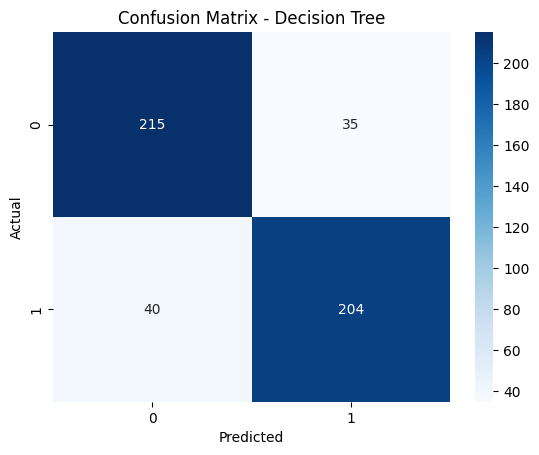



---Random Forest---
Accuracy: 0.9331983805668016
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.96      0.94       250
           1       0.96      0.90      0.93       244

    accuracy                           0.93       494
   macro avg       0.94      0.93      0.93       494
weighted avg       0.93      0.93      0.93       494



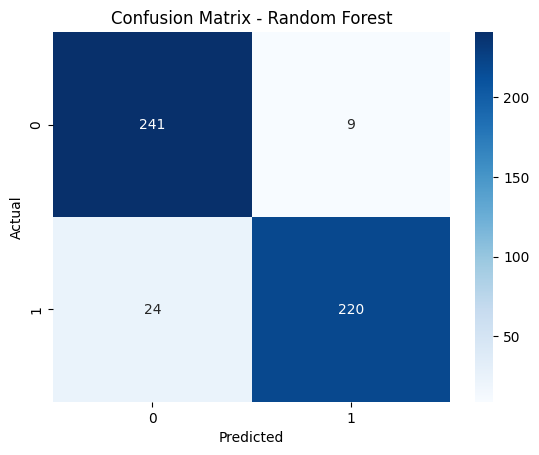



---Logistic Regression---
Accuracy: 0.7591093117408907
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.72      0.75       250
           1       0.74      0.80      0.77       244

    accuracy                           0.76       494
   macro avg       0.76      0.76      0.76       494
weighted avg       0.76      0.76      0.76       494



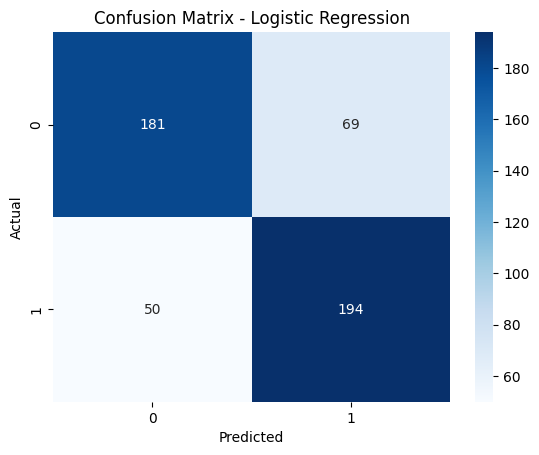

In [ ]:
def evaluate_model(y_test, y_pred, model_name):
    print(f"---{model_name}---")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.show()
    print("\n")

# Evaluate all models
evaluate_model(y_test, y_pred_dt, "Decision Tree")
evaluate_model(y_test, y_pred_rf, "Random Forest")
evaluate_model(y_test, y_pred_lr, "Logistic Regression")

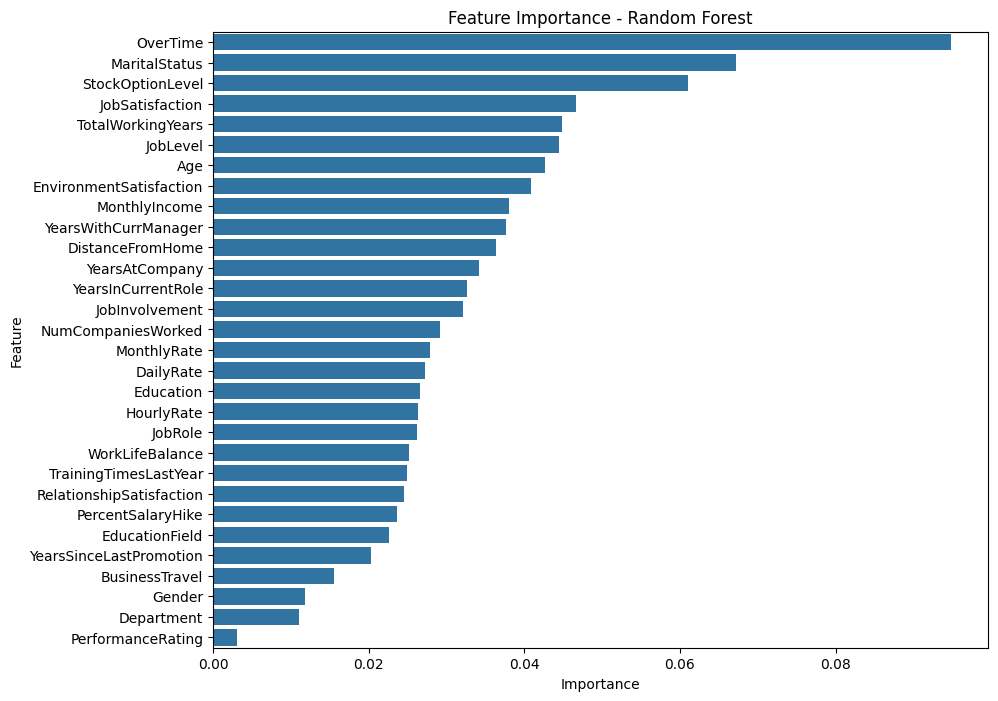

In [ ]:
importances = rf.feature_importances_
features = X.columns
feat_importance = pd.DataFrame({'Feature': features, 'Importance': importances})
feat_importance = feat_importance.sort_values(by='Importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(10,8))
sns.barplot(x='Importance', y='Feature', data=feat_importance)
plt.title("Feature Importance - Random Forest")
plt.show()

In [ ]:
new_employee = pd.DataFrame({
    'Age':[35], 'BusinessTravel':[1], 'DailyRate':[800], 'Department':[1],
    'DistanceFromHome':[10], 'Education':[3], 'EducationField':[2], 'EnvironmentSatisfaction':[3],
    'Gender':[1], 'HourlyRate':[60], 'JobInvolvement':[3], 'JobLevel':[2], 'JobRole':[4],
    'JobSatisfaction':[4], 'MaritalStatus':[1], 'MonthlyIncome':[6000], 'MonthlyRate':[15000],
    'NumCompaniesWorked':[2], 'OverTime':[1], 'PercentSalaryHike':[15], 'PerformanceRating':[3],
    'RelationshipSatisfaction':[4], 'StockOptionLevel':[1], 'TotalWorkingYears':[10],
    'TrainingTimesLastYear':[2], 'WorkLifeBalance':[3], 'YearsAtCompany':[5],
    'YearsInCurrentRole':[3], 'YearsSinceLastPromotion':[1], 'YearsWithCurrManager':[2]
})

# Ensure the columns are in the same order as training features
new_employee = new_employee[X.columns]

# Scale new employee data
new_employee_scaled = scaler.transform(new_employee)

# Predict attrition using Random Forest
prediction = rf.predict(new_employee_scaled)
result = "Will Leave" if prediction[0]==1 else "Will Stay"
print("Prediction for New Employee:", result)

Prediction for New Employee: Will Stay


In [ ]:
import ipywidgets as widgets
from IPython.display import display

# ---------- Create widgets for all 28 features ----------
age = widgets.IntSlider(description='Age', min=18, max=60, value=35)
business_travel = widgets.Dropdown(description='BusinessTravel', options=[('Non-Travel',0), ('Travel_Rarely',1), ('Travel_Frequently',2)], value=1)
daily_rate = widgets.IntText(description='DailyRate', value=800)
department = widgets.Dropdown(description='Department', options=[('Sales',0), ('R&D',1), ('HR',2)], value=1)
distance_from_home = widgets.IntSlider(description='DistanceFromHome', min=0, max=50, value=10)
education = widgets.IntSlider(description='Education', min=1, max=5, value=3)
education_field = widgets.Dropdown(description='EducationField', options=[('Life Sciences',0), ('Other',1), ('Medical',2), ('Marketing',3), ('Technical Degree',4), ('Human Resources',5)], value=2)
environment_satisfaction = widgets.IntSlider(description='EnvironmentSatisfaction', min=1, max=4, value=3)
gender = widgets.Dropdown(description='Gender', options=['Male', 'Female'], value='Male')
hourly_rate = widgets.IntText(description='HourlyRate', value=60)
job_involvement = widgets.IntSlider(description='JobInvolvement', min=1, max=4, value=3)
job_level = widgets.IntSlider(description='JobLevel', min=1, max=5, value=2)
job_role = widgets.Dropdown(description='JobRole', options=[('Sales Executive',0), ('Research Scientist',1), ('Laboratory Technician',2), ('Manufacturing Director',3), ('Healthcare Representative',4), ('Manager',5), ('Sales Representative',6), ('Research Director',7), ('Human Resources',8)], value=4)
job_satisfaction = widgets.IntSlider(description='JobSatisfaction', min=1, max=4, value=4)
marital_status = widgets.Dropdown(description='MaritalStatus', options=[('Single',0), ('Married',1), ('Divorced',2)], value=1)
monthly_income = widgets.IntText(description='MonthlyIncome', value=6000)
monthly_rate = widgets.IntText(description='MonthlyRate', value=15000)
num_companies_worked = widgets.IntSlider(description='NumCompaniesWorked', min=0, max=10, value=2)
overtime = widgets.Dropdown(description='OverTime', options=['No', 'Yes'], value='Yes')
percent_salary_hike = widgets.IntSlider(description='PercentSalaryHike', min=0, max=25, value=15)
performance_rating = widgets.IntSlider(description='PerformanceRating', min=1, max=4, value=3)
relationship_satisfaction = widgets.IntSlider(description='RelationshipSatisfaction', min=1, max=4, value=4)
stock_option_level = widgets.IntSlider(description='StockOptionLevel', min=0, max=3, value=1)
total_working_years = widgets.IntSlider(description='TotalWorkingYears', min=0, max=40, value=10)
training_times_last_year = widgets.IntSlider(description='TrainingTimesLastYear', min=0, max=10, value=2)
work_life_balance = widgets.IntSlider(description='WorkLifeBalance', min=1, max=4, value=3)
years_at_company = widgets.IntSlider(description='YearsAtCompany', min=0, max=40, value=5)
years_in_current_role = widgets.IntSlider(description='YearsInCurrentRole', min=0, max=20, value=3)
years_since_last_promotion = widgets.IntSlider(description='YearsSinceLastPromotion', min=0, max=15, value=1)
years_with_curr_manager = widgets.IntSlider(description='YearsWithCurrManager', min=0, max=20, value=2)

display(age, business_travel, daily_rate, department, distance_from_home, education, education_field,
        environment_satisfaction, gender, hourly_rate, job_involvement, job_level, job_role, job_satisfaction,
        marital_status, monthly_income, monthly_rate, num_companies_worked, overtime, percent_salary_hike,
        performance_rating, relationship_satisfaction, stock_option_level, total_working_years,
        training_times_last_year, work_life_balance, years_at_company, years_in_current_role,
        years_since_last_promotion, years_with_curr_manager)


button = widgets.Button(description="Predict Attrition")
output = widgets.Output()
display(button, output)

def predict_attrition_full(b):
    new_emp_dict = {
        'Age':[age.value],
        'BusinessTravel':[business_travel.value],
        'DailyRate':[daily_rate.value],
        'Department':[department.value],
        'DistanceFromHome':[distance_from_home.value],
        'Education':[education.value],
        'EducationField':[education_field.value],
        'EnvironmentSatisfaction':[environment_satisfaction.value],
        'Gender':[1 if gender.value=='Male' else 0],
        'HourlyRate':[hourly_rate.value],
        'JobInvolvement':[job_involvement.value],
        'JobLevel':[job_level.value],
        'JobRole':[job_role.value],
        'JobSatisfaction':[job_satisfaction.value],
        'MaritalStatus':[marital_status.value],
        'MonthlyIncome':[monthly_income.value],
        'MonthlyRate':[monthly_rate.value],
        'NumCompaniesWorked':[num_companies_worked.value],
        'OverTime':[1 if overtime.value=='Yes' else 0],
        'PercentSalaryHike':[percent_salary_hike.value],
        'PerformanceRating':[performance_rating.value],
        'RelationshipSatisfaction':[relationship_satisfaction.value],
        'StockOptionLevel':[stock_option_level.value],
        'TotalWorkingYears':[total_working_years.value],
        'TrainingTimesLastYear':[training_times_last_year.value],
        'WorkLifeBalance':[work_life_balance.value],
        'YearsAtCompany':[years_at_company.value],
        'YearsInCurrentRole':[years_in_current_role.value],
        'YearsSinceLastPromotion':[years_since_last_promotion.value],
        'YearsWithCurrManager':[years_with_curr_manager.value]
    }

    # Convert to DataFrame
    new_employee_df = pd.DataFrame(new_emp_dict)

    # Ensure correct column order
    new_employee_df = new_employee_df[X.columns]

    new_employee_scaled = scaler.transform(new_employee_df)

    prediction = rf.predict(new_employee_scaled)
    result = "Will Leave ❌" if prediction[0]==1 else "Will Stay ✅"

    # Output result
    with output:
        output.clear_output()
        print(f"Prediction for this Employee: {result}")

button.on_click(predict_attrition_full)


IntSlider(value=35, description='Age', max=60, min=18)

Dropdown(description='BusinessTravel', index=1, options=(('Non-Travel', 0), ('Travel_Rarely', 1), ('Travel_Fre…

IntText(value=800, description='DailyRate')

Dropdown(description='Department', index=1, options=(('Sales', 0), ('R&D', 1), ('HR', 2)), value=1)

IntSlider(value=10, description='DistanceFromHome', max=50)

...

IntSlider(value=3, description='YearsInCurrentRole', max=20)

IntSlider(value=1, description='YearsSinceLastPromotion', max=15)

IntSlider(value=2, description='YearsWithCurrManager', max=20)

Button(description='Predict Attrition', style=ButtonStyle())

Output()

In [ ]:
# High-Risk Employee DataFrame
high_risk_employee = pd.DataFrame({
    'Age':[25],
    'BusinessTravel':[2],
    'DailyRate':[400],
    'Department':[0],
    'DistanceFromHome':[25],
    'Education':[2],
    'EducationField':[2],
    'EnvironmentSatisfaction':[1],
    'Gender':[1],
    'HourlyRate':[50],
    'JobInvolvement':[1],
    'JobLevel':[1],
    'JobRole':[0],
    'JobSatisfaction':[1],
    'MaritalStatus':[0],
    'MonthlyIncome':[3000],
    'MonthlyRate':[10000],
    'NumCompaniesWorked':[4],
    'OverTime':[1],
    'PercentSalaryHike':[10],
    'PerformanceRating':[1],
    'RelationshipSatisfaction':[1],
    'StockOptionLevel':[0],
    'TotalWorkingYears':[2],
    'TrainingTimesLastYear':[0],
    'WorkLifeBalance':[1],
    'YearsAtCompany':[1],
    'YearsInCurrentRole':[1],
    'YearsSinceLastPromotion':[3],
    'YearsWithCurrManager':[1]
})

high_risk_employee = high_risk_employee[X.columns]

high_risk_scaled = scaler.transform(high_risk_employee)

prediction = rf.predict(high_risk_scaled)
result = "Will Leave ❌" if prediction[0]==1 else "Will Stay ✅"
print("Prediction for this High-Risk Employee:", result)


Prediction for this High-Risk Employee: Will Leave ❌


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output

# --- Profile Presets ---
high_risk_profile = {
    'Age':25, 'BusinessTravel':2, 'DailyRate':400, 'Department':0,
    'DistanceFromHome':25, 'Education':2, 'EducationField':2,
    'EnvironmentSatisfaction':1, 'Gender':1, 'HourlyRate':50,
    'JobInvolvement':1, 'JobLevel':1, 'JobRole':0, 'JobSatisfaction':1,
    'MaritalStatus':0, 'MonthlyIncome':3000, 'MonthlyRate':10000,
    'NumCompaniesWorked':4, 'OverTime':1, 'PercentSalaryHike':10,
    'PerformanceRating':1, 'RelationshipSatisfaction':1, 'StockOptionLevel':0,
    'TotalWorkingYears':2, 'TrainingTimesLastYear':0, 'WorkLifeBalance':1,
    'YearsAtCompany':1, 'YearsInCurrentRole':1, 'YearsSinceLastPromotion':3,
    'YearsWithCurrManager':1
}

low_risk_profile = {
    'Age':40, 'BusinessTravel':0, 'DailyRate':900, 'Department':1,
    'DistanceFromHome':5, 'Education':3, 'EducationField':1,
    'EnvironmentSatisfaction':4, 'Gender':0, 'HourlyRate':75,
    'JobInvolvement':4, 'JobLevel':3, 'JobRole':7, 'JobSatisfaction':4,
    'MaritalStatus':1, 'MonthlyIncome':9500, 'MonthlyRate':20000,
    'NumCompaniesWorked':1, 'OverTime':0, 'PercentSalaryHike':20,
    'PerformanceRating':4, 'RelationshipSatisfaction':4, 'StockOptionLevel':2,
    'TotalWorkingYears':15, 'TrainingTimesLastYear':3, 'WorkLifeBalance':4,
    'YearsAtCompany':10, 'YearsInCurrentRole':6, 'YearsSinceLastPromotion':1,
    'YearsWithCurrManager':5
}

# --- Dropdown to select preset ---
profile_selector = widgets.Dropdown(
    options=['Custom', 'High-Risk Employee', 'Low-Risk Employee'],
    description='Profile Type:'
)

# --- Key feature inputs (you can expand if you want all features) ---
age = widgets.IntSlider(description='Age', min=18, max=60, value=35)
income = widgets.IntText(description='Monthly Income', value=6000)
overtime = widgets.Dropdown(description='OverTime', options=['No', 'Yes'], value='No')
job_satisfaction = widgets.IntSlider(description='Job Satisfaction', min=1, max=4, value=3)
worklife = widgets.IntSlider(description='WorkLife Balance', min=1, max=4, value=3)
years_at_company = widgets.IntSlider(description='Years At Company', min=0, max=40, value=5)

predict_btn = widgets.Button(description='Predict Attrition', button_style='info')
output = widgets.Output()

# --- Display widgets ---
display(profile_selector, age, income, overtime, job_satisfaction, worklife, years_at_company, predict_btn, output)

# --- Function to fill preset values ---
def load_profile(profile_name):
    if profile_name == 'High-Risk Employee':
        profile = high_risk_profile
    elif profile_name == 'Low-Risk Employee':
        profile = low_risk_profile
    else:
        return
    # Set key visible fields
    age.value = profile['Age']
    income.value = profile['MonthlyIncome']
    overtime.value = 'Yes' if profile['OverTime'] == 1 else 'No'
    job_satisfaction.value = profile['JobSatisfaction']
    worklife.value = profile['WorkLifeBalance']
    years_at_company.value = profile['YearsAtCompany']

profile_selector.observe(lambda change: load_profile(change['new']), names='value')

# --- Prediction logic ---
def predict_attrition(b):
    # Build input dictionary using key + defaults
    employee = low_risk_profile.copy()  # use low-risk defaults
    employee.update({
        'Age': age.value,
        'MonthlyIncome': income.value,
        'OverTime': 1 if overtime.value == 'Yes' else 0,
        'JobSatisfaction': job_satisfaction.value,
        'WorkLifeBalance': worklife.value,
        'YearsAtCompany': years_at_company.value
    })

    # Convert to DataFrame and reorder columns
    new_df = pd.DataFrame([employee])[X.columns]

    # Scale and predict
    new_scaled = scaler.transform(new_df)
    pred = rf.predict(new_scaled)[0]

    # Output result
    with output:
        clear_output()
        result = "Will Leave ❌" if pred == 1 else "Will Stay ✅"
        print(f"Prediction for this Employee: {result}")
        if pred == 1:
            print("⚠️ High attrition risk. Consider improving satisfaction, pay, or work-life balance.")
        else:
            print("✅ Low attrition risk. Employee likely to stay.")

predict_btn.on_click(predict_attrition)


Dropdown(description='Profile Type:', options=('Custom', 'High-Risk Employee', 'Low-Risk Employee'), value='Cu…

IntSlider(value=35, description='Age', max=60, min=18)

IntText(value=6000, description='Monthly Income')

Dropdown(description='OverTime', options=('No', 'Yes'), value='No')

IntSlider(value=3, description='Job Satisfaction', max=4, min=1)

IntSlider(value=3, description='WorkLife Balance', max=4, min=1)

IntSlider(value=5, description='Years At Company', max=40)

Button(button_style='info', description='Predict Attrition', style=ButtonStyle())

Output()

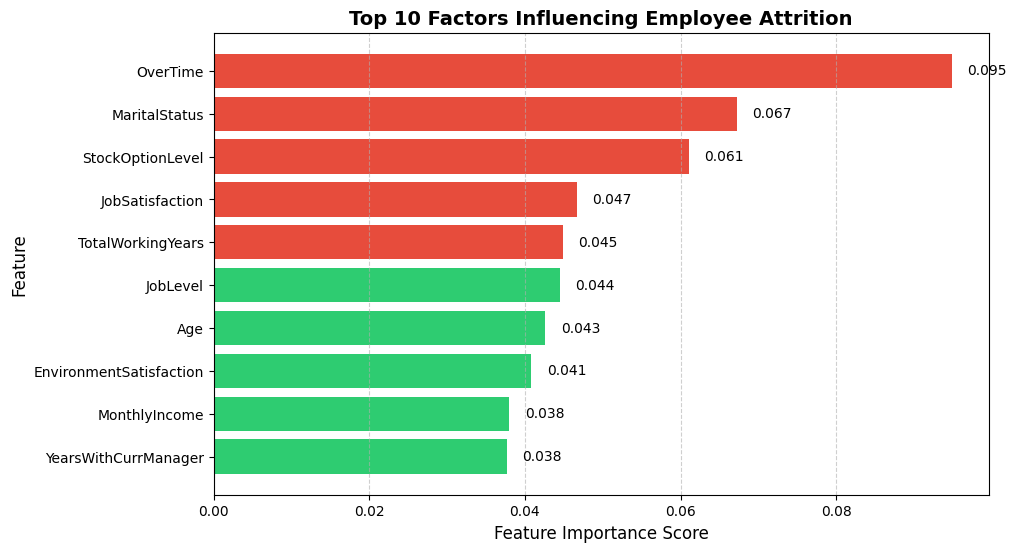

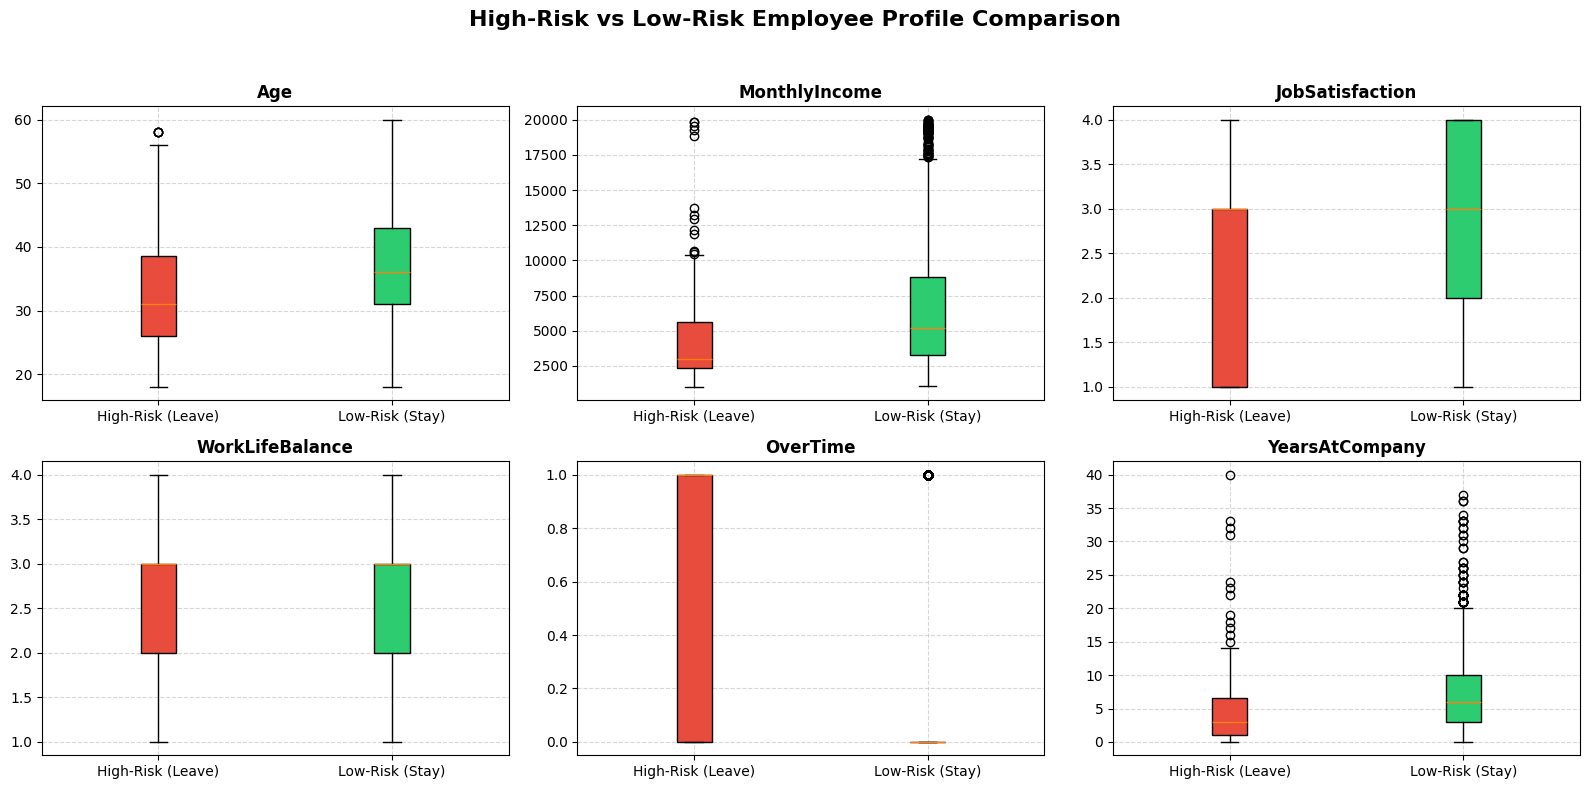


### 📊 HR Insights Summary
- 🔴 **OverTime**, **JobSatisfaction**, and **WorkLifeBalance** are strong indicators of attrition.
- 🧠 Employees with **low satisfaction**, **poor balance**, and **low income** tend to leave.
- 🟢 **Older**, **experienced**, and **well-compensated** employees generally stay longer.
- 🕓 Short-tenure employees (**YearsAtCompany < 3**) show higher turnover risk.
- 💡 HR can reduce attrition by focusing on:
  - Flexible schedules for overtime employees  
  - Improving job satisfaction through recognition & career growth  
  - Reviewing salary gaps and promotion timelines


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------- 1️⃣ Feature Importance Visualization ----------
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
top_features = X.columns[indices][:10]
top_importances = importances[indices][:10]

plt.figure(figsize=(10,6))
bars = plt.barh(top_features[::-1], top_importances[::-1],
                color=['#2ecc71' if imp < np.median(top_importances) else '#e74c3c'
                       for imp in top_importances[::-1]])
plt.title("Top 10 Factors Influencing Employee Attrition", fontsize=14, weight='bold')
plt.xlabel("Feature Importance Score", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

# Annotate bars
for bar in bars:
    plt.text(bar.get_width()+0.002, bar.get_y() + bar.get_height()/2,
             f"{bar.get_width():.3f}", va='center', fontsize=10)

plt.show()

# ---------- 2️⃣ High-Risk vs Low-Risk Comparison ----------
# Add predictions
y_pred = rf.predict(scaler.transform(X))
df_with_pred = X.copy()
df_with_pred['Predicted_Attrition'] = y_pred

# Separate groups
high_risk = df_with_pred[df_with_pred['Predicted_Attrition']==1]
low_risk  = df_with_pred[df_with_pred['Predicted_Attrition']==0]

# Select HR-focused features
features = ['Age', 'MonthlyIncome', 'JobSatisfaction',
            'WorkLifeBalance', 'OverTime', 'YearsAtCompany']

fig, axes = plt.subplots(2, 3, figsize=(16,8))
axes = axes.flatten()

for i, feature in enumerate(features):
    ax = axes[i]
    # Plot boxplot
    bp = ax.boxplot([high_risk[feature], low_risk[feature]],
                    patch_artist=True,
                    labels=['High-Risk (Leave)', 'Low-Risk (Stay)'])
    colors = ['#e74c3c', '#2ecc71']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    ax.set_title(feature, fontsize=12, weight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("High-Risk vs Low-Risk Employee Profile Comparison", fontsize=16, weight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# ---------- 3️⃣ Insights Summary ----------
from IPython.display import display, Markdown

display(Markdown("""
### 📊 HR Insights Summary
- 🔴 **OverTime**, **JobSatisfaction**, and **WorkLifeBalance** are strong indicators of attrition.
- 🧠 Employees with **low satisfaction**, **poor balance**, and **low income** tend to leave.
- 🟢 **Older**, **experienced**, and **well-compensated** employees generally stay longer.
- 🕓 Short-tenure employees (**YearsAtCompany < 3**) show higher turnover risk.
- 💡 HR can reduce attrition by focusing on:
  - Flexible schedules for overtime employees
  - Improving job satisfaction through recognition & career growth
  - Reviewing salary gaps and promotion timelines
"""))


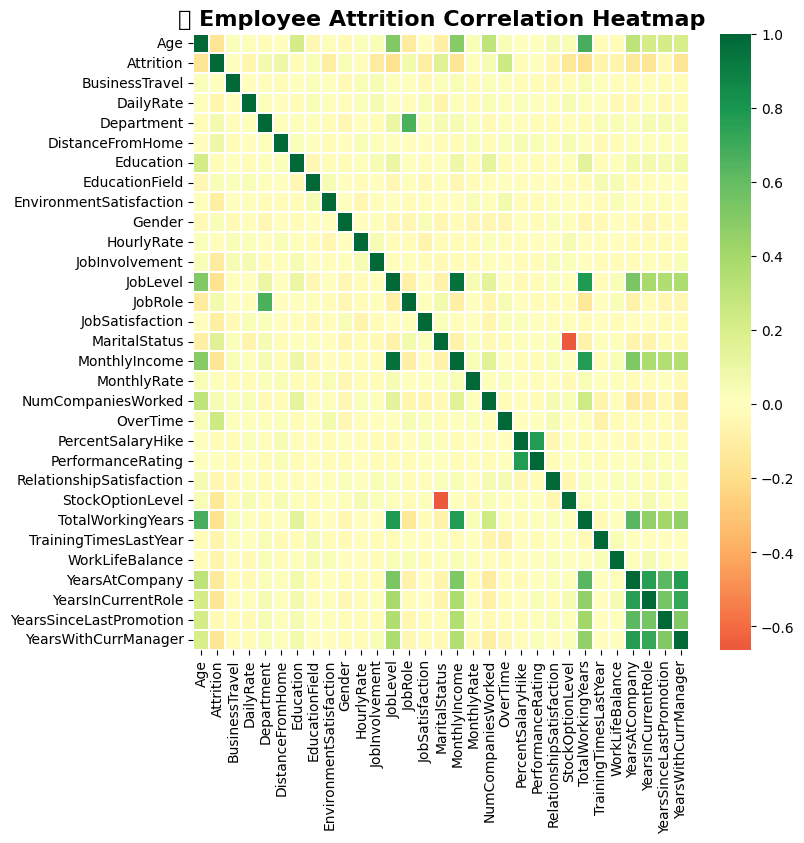

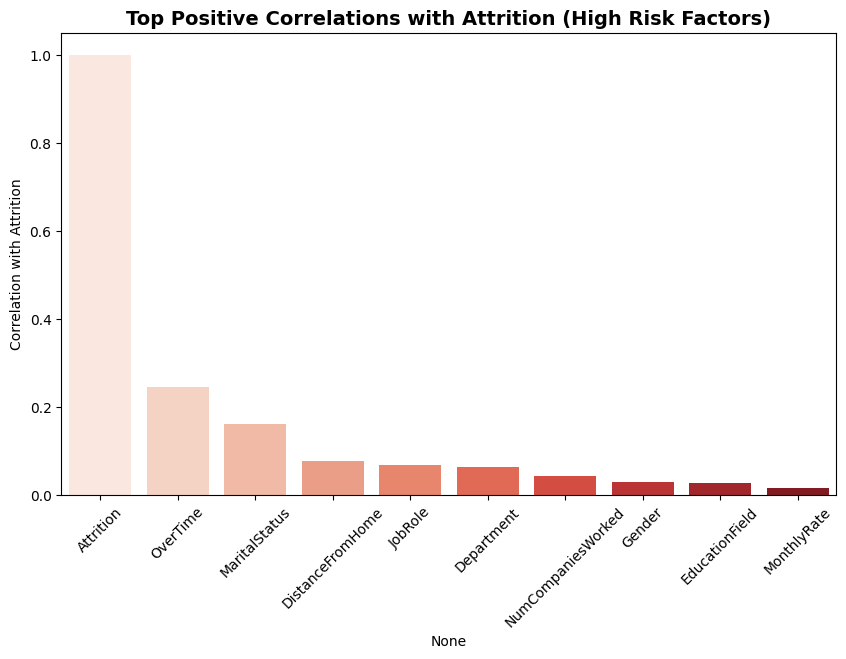

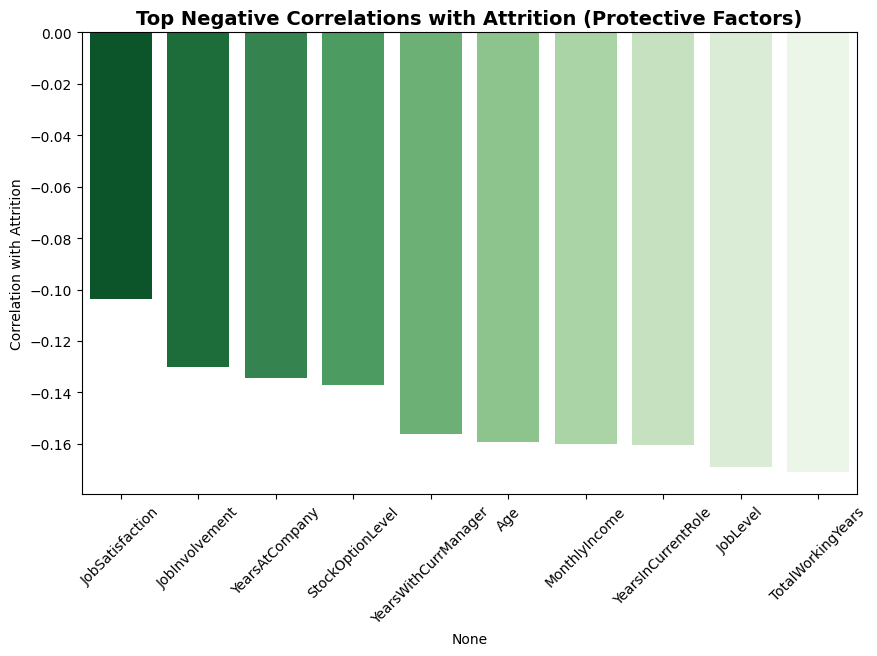

In [ ]:
# =========================================================
# 🔹 Step 15: Attrition Heatmap Visualization
# =========================================================
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Combine features and target for correlation
df_corr = df.copy()
# Ensure 'Attrition' column is numeric for correlation calculation
df_corr['Attrition'] = df_corr['Attrition'].map({0: 0, 1: 1}) # Assuming it's already encoded as 0 and 1

# Select only numeric columns
numeric_features = df_corr.select_dtypes(include=['int64', 'float64'])

# Compute correlations
corr = numeric_features.corr()['Attrition'].sort_values(ascending=False)

# Top correlated features (positive & negative)
# Use pd.concat instead of append
top_corr = pd.concat([corr.head(10), corr.tail(10)])

plt.figure(figsize=(8,8))
sns.heatmap(numeric_features.corr(), cmap='RdYlGn', center=0, annot=False, linewidths=0.2)
plt.title("🔥 Employee Attrition Correlation Heatmap", fontsize=16, weight='bold')
plt.show()

# Focused bar plot for clarity
plt.figure(figsize=(10,6))
# Ensure we only plot the top 10 positive correlations
sns.barplot(x=corr.index[:10], y=corr.values[:10], palette='Reds')
plt.title("Top Positive Correlations with Attrition (High Risk Factors)", fontsize=14, weight='bold')
plt.xticks(rotation=45)
plt.ylabel("Correlation with Attrition")
plt.show()

plt.figure(figsize=(10,6))
# Ensure we only plot the bottom 10 negative correlations
sns.barplot(x=corr.index[-10:], y=corr.values[-10:], palette='Greens_r')
plt.title("Top Negative Correlations with Attrition (Protective Factors)", fontsize=14, weight='bold')
plt.xticks(rotation=45)
plt.ylabel("Correlation with Attrition")
plt.show()